# Clasificación de vinos mediante regresión logística

Ejemplo para el curso de Inteligencia Artificial.

## 1. Descripción del problema y objetivo

El conjunto de datos Wine contiene resultados de análisis químicos de 178 muestras de vino pertenecientes a tres clases (0, 1 y 2). Cada muestra tiene 13 características numéricas, como el contenido de alcohol, la acidez y la intensidad del color. Las clases representan tres cultivares y no niveles de calidad.

El objetivo consiste en predecir la clase del vino a partir de sus características químicas. Se implementará regresión logística multiclase y se comparará la regularización L2 con la regularización L1, equivalente a una penalización de tipo Lasso. La evaluación utilizará únicamente accuracy y matriz de confusión.

## 2. Inspección inicial del conjunto de datos

El dataset se carga directamente desde Scikit-learn. Se revisan las primeras filas, dimensiones, tipos de datos y estadísticas descriptivas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()

print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [4]:
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


### 2.1 Valores faltantes y registros duplicados

Se comprueba la calidad inicial del conjunto de datos. Las observaciones duplicadas deben revisarse antes de decidir su eliminación.

In [5]:
print("Valores faltantes por columna:")
print(df.isna().sum())
print("Registros duplicados:", df.duplicated().sum())

Valores faltantes por columna:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64
Registros duplicados: 0


El conjunto de datos Wine contiene 178 observaciones y 14 columnas, de las cuales 13 corresponden a variables predictoras numéricas que describen diferentes propiedades químicas de los vinos, mientras que target representa la clase que se desea predecir, codificada mediante los valores 0, 1 y 2. Este dataset no contiene valores faltantes ni registros duplicados

## 3. Análisis exploratorio

La variable objetivo es `target`, que toma los valores 0, 1 y 2. Se estudia la distribución de clases y de las características. Para evitar muchas gráficas, se muestran cuatro variables numéricas representativas; las 13 se conservan para entrenar los modelos.

### 3.1 Distribución de la variable objetivo

Cantidad por clase:
target
0    59
1    71
2    48
Name: count, dtype: int64


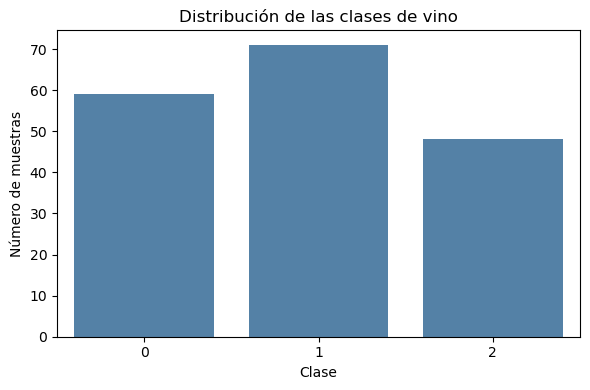

In [6]:
print("Cantidad por clase:")
print(df["target"].value_counts().sort_index())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target", order=[0, 1, 2], color="steelblue")
plt.title("Distribución de las clases de vino")
plt.xlabel("Clase")
plt.ylabel("Número de muestras")
plt.tight_layout()
plt.show()

### 3.2 Histogramas de las variables predictoras

Se inspeccionan visualmente algunas características para identificar diferencias de escala y forma de sus distribuciones.

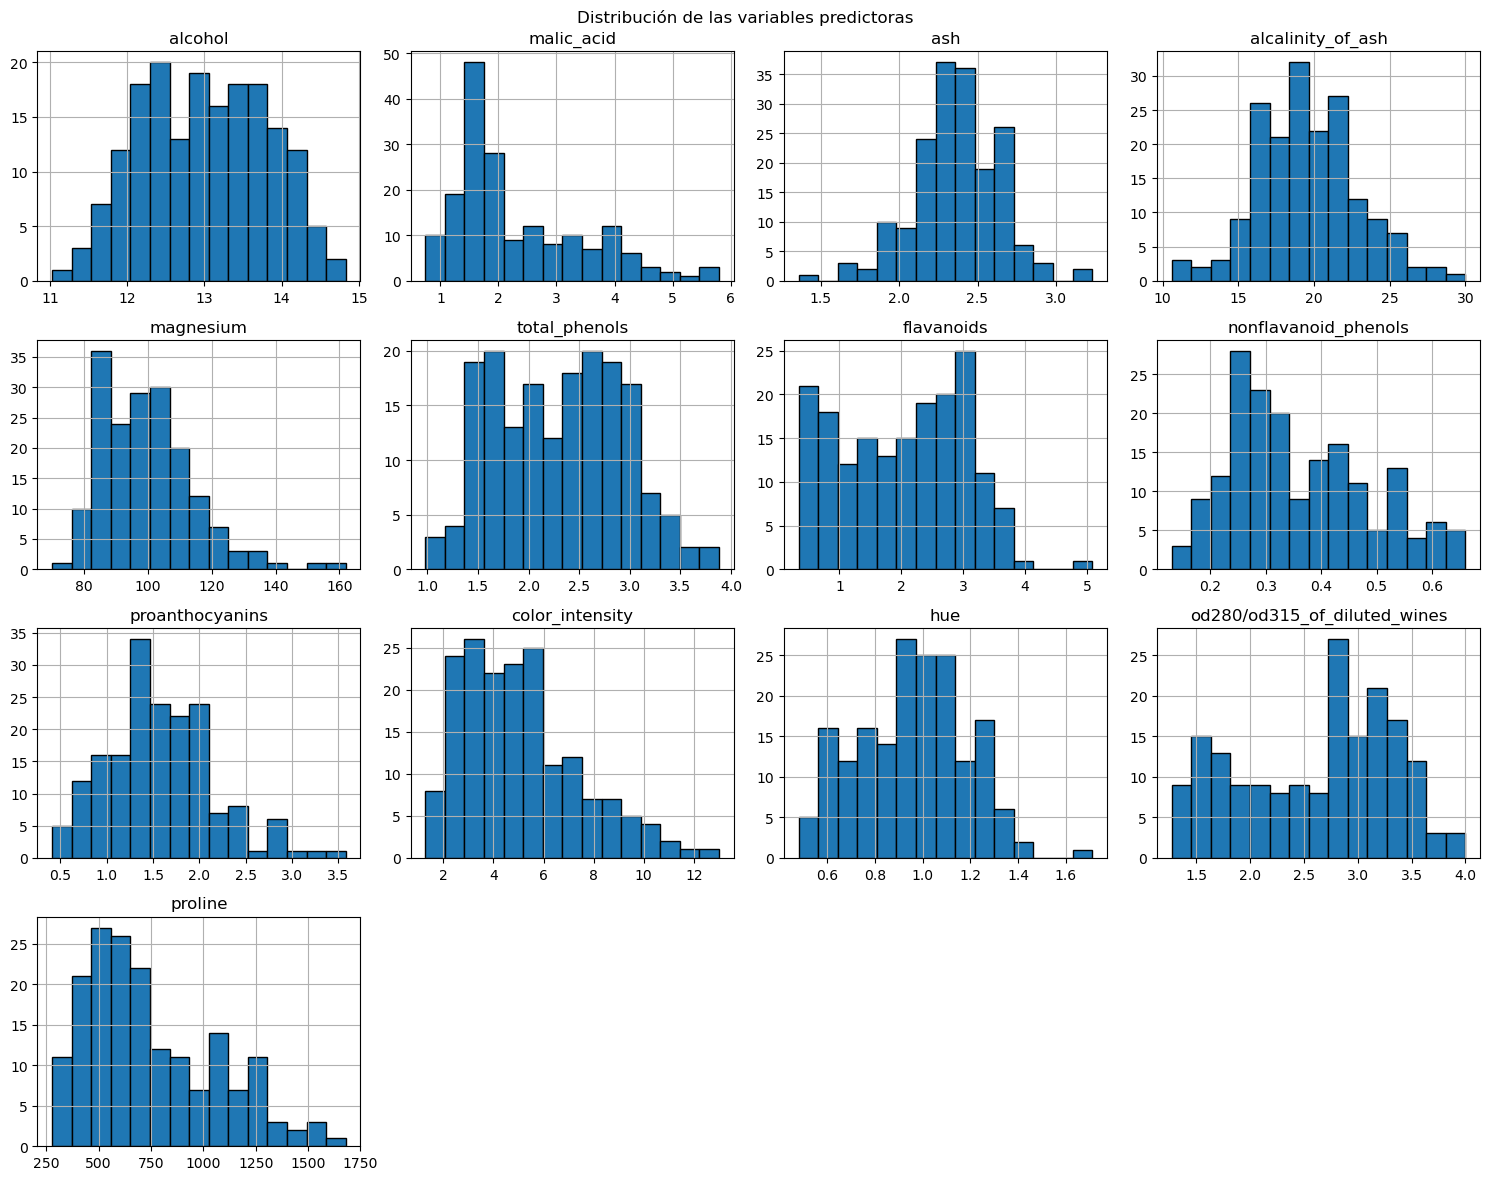

In [9]:
variables_predictoras = df.drop(columns=["target"]).columns

df[variables_predictoras].hist(figsize=(15, 12), bins=15, edgecolor="black")

plt.suptitle("Distribución de las variables predictoras")
plt.tight_layout()
plt.show()

### 3.3 Diagramas de cajas

Estos diagramas permiten observar la dispersión y detectar posibles valores atípicos. Un valor atípico no debe eliminarse automáticamente.

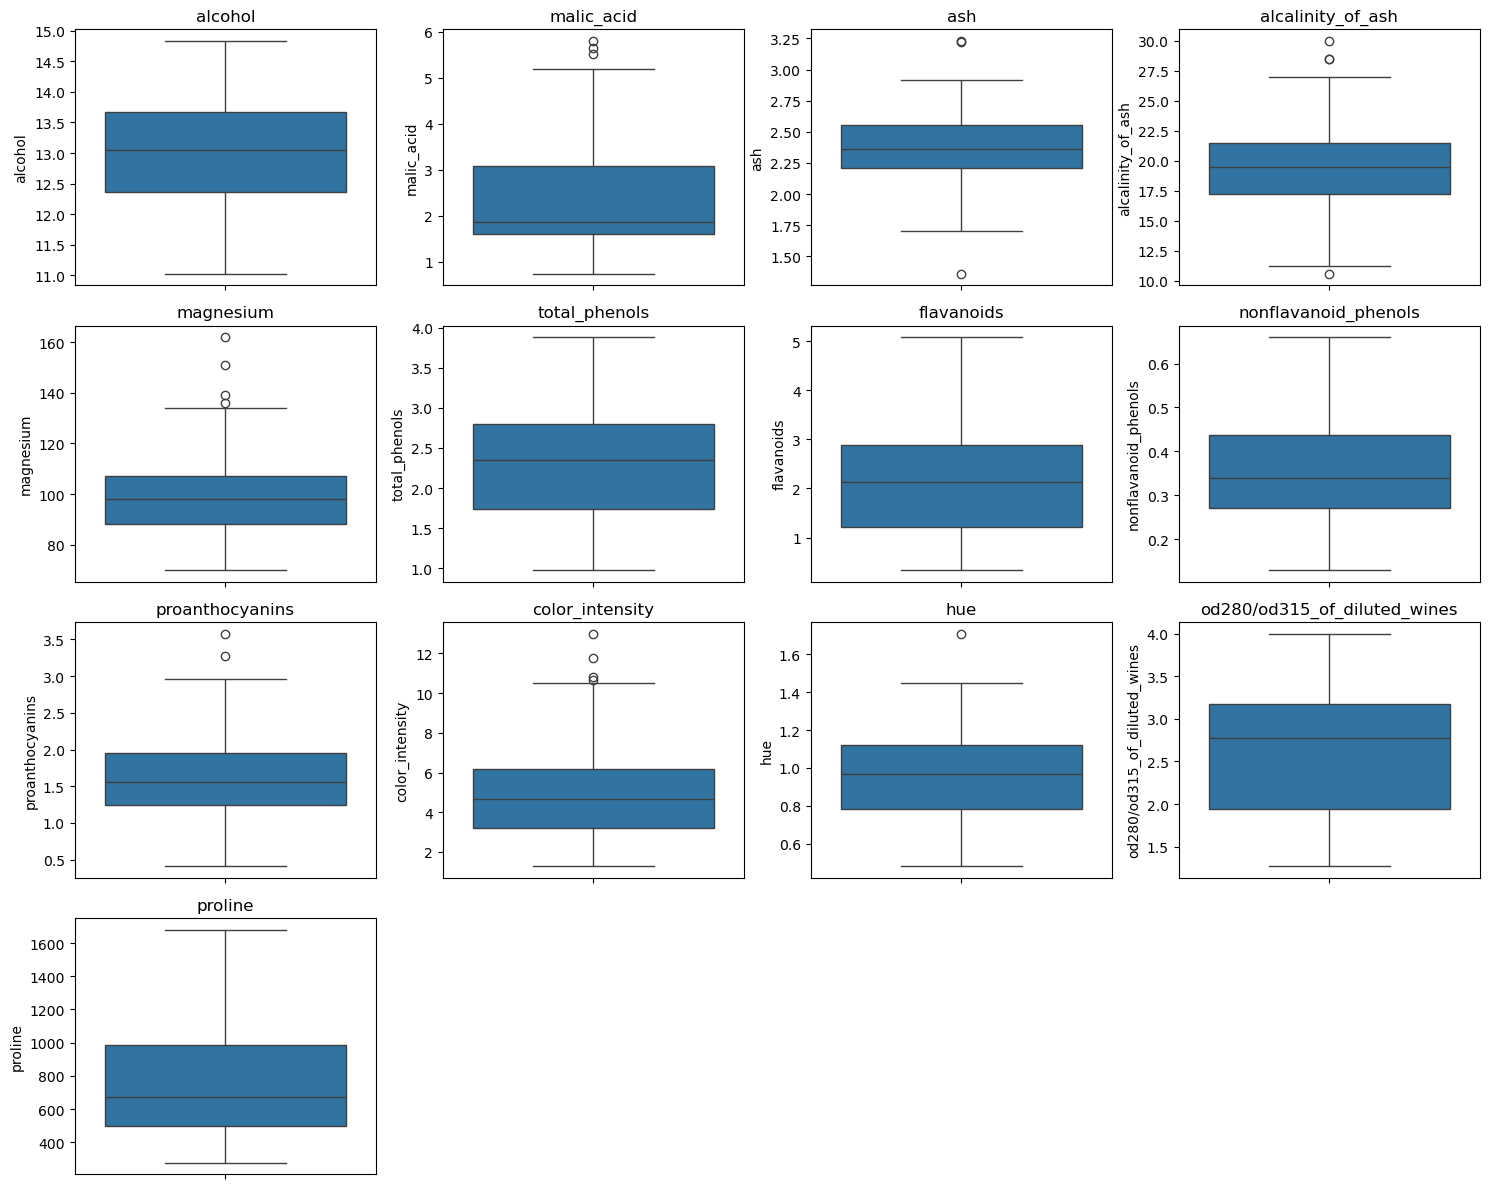

In [10]:
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
axes = axes.flatten()

for i, variable in enumerate(variables_predictoras):
    sns.boxplot(y=df[variable], ax=axes[i])
    axes[i].set_title(variable)

for j in range(len(variables_predictoras), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### 3.4 Correlación entre variables predictoras

Se calcula la correlación de Pearson de las 13 variables numéricas. Una correlación alta no obliga a eliminar características, pero permite identificar posibles redundancias. `target` no se incluye en esta matriz porque sus etiquetas representan categorías.

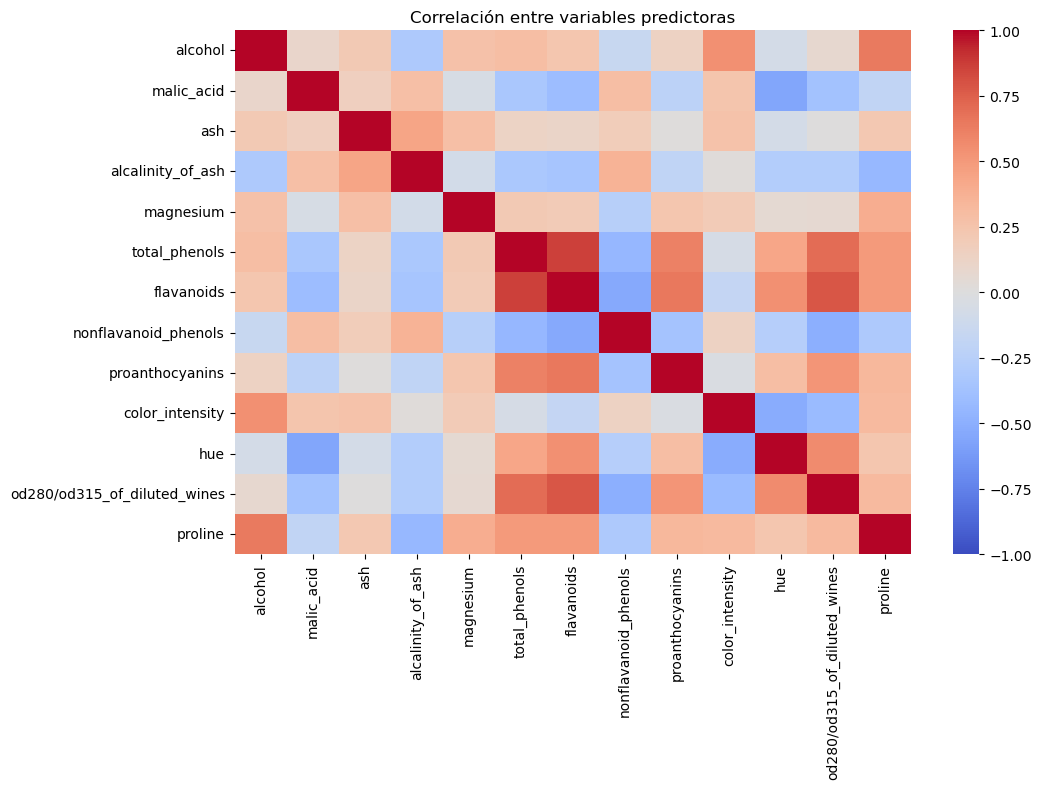

In [11]:
variables_predictoras = wine.feature_names
correlaciones = df[variables_predictoras].corr(method="pearson")

plt.figure(figsize=(11, 8))
sns.heatmap(correlaciones, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlación entre variables predictoras")
plt.tight_layout()
plt.show()

In [14]:
mascara = np.triu(np.ones(correlaciones.shape), k=1).astype(bool)

# Obtener las correlaciones entre parejas de variables
correlaciones = correlaciones.where(mascara).stack().reset_index()
correlaciones.columns = ["Variable 1", "Variable 2", "Correlación"]

# Ordenar por la magnitud de la correlación
correlaciones["Correlación absoluta"] = correlaciones["Correlación"].abs()
top5 = correlaciones.sort_values(by="Correlación absoluta", ascending=False).head(5)
top5.round(3)

,Variable 1,Variable 2,Correlación,Correlación absoluta
50,total_phenols,flavanoids,0.865,0.865
61,flavanoids,od280/od315_of_diluted_wines,0.787,0.787
55,total_phenols,od280/od315_of_diluted_wines,0.700,0.700
58,flavanoids,proanthocyanins,0.653,0.653
11,alcohol,proline,0.644,0.644


La variable objetivo `target` presenta una distribución relativamente equilibrada entre las tres clases, con 59, 71 y 48 observaciones, respectivamente. Aunque existen diferencias en el número de muestras, no se observa un desbalance severo entre las clases.

Los histogramas muestran que las variables predictoras presentan distribuciones diferentes, algunas aproximadamente simétricas y otras con asimetrías, como `malic_acid`, `color_intensity` y `proline`. También se observan diferencias importantes en sus escalas y dispersión, lo que justifica utilizar estandarización antes de entrenar los modelos de regresión logística.

Los diagramas de cajas permiten identificar posibles valores atípicos en variables como `malic_acid`, `magnesium`, `color_intensity` y `proanthocyanins`. Sin embargo, estos valores no necesariamente representan errores y, por tanto, no se eliminarán sin evidencia adicional que justifique hacerlo.

El análisis de correlación de Pearson muestra que la relación más fuerte se presenta entre `total_phenols` y `flavanoids` (r = 0.865), seguida de `flavanoids` y `od280/od315_of_diluted_wines` (r = 0.787), y `total_phenols` y `od280/od315_of_diluted_wines` (r = 0.700). Estas correlaciones positivas indican que algunas características químicas tienden a variar conjuntamente; pero no implica necesariamente que deban eliminarse.

En conclusión, se conservarán las 13 variables predictoras para entrenar inicialmente la regresión logística. Posteriormente, se analizará si la regularización L1 permite reducir la cantidad de coeficientes diferentes de cero sin deteriorar considerablemente el rendimiento de clasificación.

## 4. Preparación de los datos

Se separan las características (`X`) y la clase (`y`). Se reserva el 20 % de las muestras para prueba. Se utiliza `stratify=y` para conservar aproximadamente la proporción de cada clase en ambos conjuntos.

Después se estandarizan las variables predictoras. `StandardScaler` se ajusta solo con los datos de entrenamiento, para evitar fuga de información hacia el modelo.

In [15]:
X = df[variables_predictoras].copy()
y = df["target"].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Clases en entrenamiento:")
print(y_train.value_counts().sort_index())
print("Clases en prueba:")
print(y_test.value_counts().sort_index())

Entrenamiento: (142, 13)
Prueba: (36, 13)
Clases en entrenamiento:
target
0    47
1    57
2    38
Name: count, dtype: int64
Clases en prueba:
target
0    12
1    14
2    10
Name: count, dtype: int64


In [16]:
scaler = StandardScaler()

X_train_preparado = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_preparado = pd.DataFrame(scaler.transform(X_test),columns=X_test.columns, index=X_test.index)

X_train_preparado.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
36,0.385801,-0.637871,1.776668,-1.224532,0.696430,0.526865,0.732292,-0.169549,-0.415783,-0.167467,0.624378,0.252908,0.467725
30,0.948519,-0.765445,1.253174,0.853284,0.091785,1.172795,1.333181,-0.590457,1.349742,0.305303,1.067155,0.151048,1.815768
26,0.523354,-0.519409,0.954034,-1.046433,-0.445678,0.930572,1.006382,-0.169549,-0.260002,-0.081509,-0.128343,0.893172,1.516203
12,0.973529,-0.555859,0.168793,-1.076116,-0.714409,0.526865,0.816627,-0.590457,0.363125,0.262324,0.890044,0.427526,1.932265
148,0.435820,0.820120,0.056615,0.556453,-0.512860,-0.555068,-1.291756,0.756449,-0.606183,1.474335,-1.766619,-1.435059,-0.297831


## 5. Regresión logística sin regularización
Inicialmente entrenaremos un modelo de regresión logística utilizando las 13 variables predictoras del conjunto de datos Wine, sin aplicar regularización.
La regresión logística es un algoritmo de aprendizaje supervisado que permite resolver problemas de clasificación. Aunque su nombre incluye el término regresión, su objetivo es estimar probabilidades de pertenencia a diferentes clases y utilizarlas para realizar predicciones.
En este caso, el modelo debe clasificar cada muestra de vino en una de las tres clases disponibles, utilizando sus características químicas.
Este primer modelo servirá como referencia para comparar posteriormente los efectos de la regularización L2 y L1 sobre los coeficientes y el rendimiento de clasificación.

In [18]:
modelo_sin_reg = LogisticRegression(C=np.inf, solver="newton-cg", max_iter=1000)
modelo_sin_reg.fit(X_train_preparado, y_train)

LogisticRegression(C=inf, max_iter=1000, solver='newton-cg')

Accuracy entrenamiento: 1.0000
Accuracy prueba: 0.9722


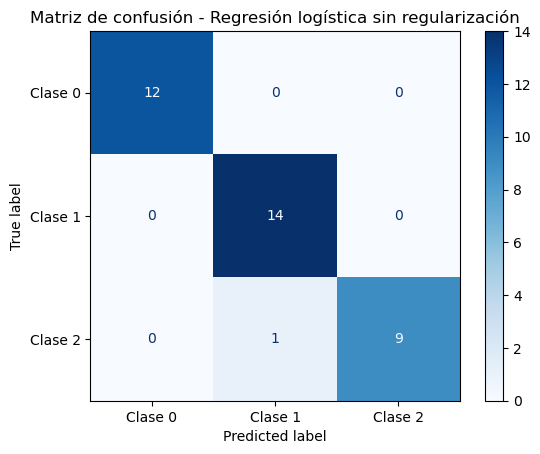

In [19]:
pred_train = modelo_sin_reg.predict(X_train_preparado)
pred_test = modelo_sin_reg.predict(X_test_preparado)

# Accuracy
accuracy_train = accuracy_score(y_train, pred_train)
accuracy_test = accuracy_score(y_test, pred_test)

print(f"Accuracy entrenamiento: {accuracy_train:.4f}")
print(f"Accuracy prueba: {accuracy_test:.4f}")

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["Clase 0", "Clase 1", "Clase 2"], cmap="Blues")

plt.title("Matriz de confusión - Regresión logística sin regularización")
plt.show()

## 6. Regresión logística con regularización L2

`LogisticRegression` usa por defecto regularización L2. El parámetro `C` controla la fuerza de la regularización: valores menores de `C` implican mayor regularización.

In [20]:
modelo_l2 = LogisticRegression(C=1.0, solver="newton-cg", max_iter=5000)
modelo_l2.fit(X_train_preparado, y_train)

pred_l2 = modelo_l2.predict(X_test_preparado)

print("Primeras clases predichas:", pred_l2[:10])
print("Probabilidades de las primeras 3 muestras:")
print(pd.DataFrame(modelo_l2.predict_proba(X_test_preparado.iloc[:3]), columns=[f"Clase {clase}" for clase in modelo_l2.classes_]).round(3))

Primeras clases predichas: [0 1 0 1 1 0 0 1 1 2]
Probabilidades de las primeras 3 muestras:
   Clase 0  Clase 1  Clase 2
0    1.000    0.000    0.000
1    0.007    0.540    0.453
2    0.992    0.008    0.000


### 6.1 Exploración manual del parámetro C

Se prueban distintos valores de `C` usando únicamente los datos de entrenamiento.

In [24]:
resultados_l2 = []

for C in [0.01, 0.1, 1, 10, 100]:
    modelo = LogisticRegression(C=C, solver="newton-cg", max_iter=5000)
    modelo.fit(X_train_preparado, y_train)
    pred_train = modelo.predict(X_train_preparado)
    resultados_l2.append({"C": C, "Accuracy entrenamiento": accuracy_score(y_train, pred_train)})

pd.DataFrame(resultados_l2).round(4)

,C,Accuracy entrenamiento
0,0.01,0.9859
1,0.10,0.9930
2,1.00,1.0000
3,10.00,1.0000
4,100.00,1.0000


### 6.2 Evaluación con accuracy y matriz de confusión

Accuracy es la proporción de observaciones clasificadas correctamente. La matriz de confusión muestra las clases reales en filas y las predichas en columnas.

In [30]:
df_l2 = pd.DataFrame(resultados_l2)
mejor_C_l2 = df_l2.loc[df_l2["Accuracy entrenamiento"].idxmax(), "C"]
print("Mejor C encontrado para L2:", mejor_C_l2)

Mejor C encontrado para L2: 1.0


Modelo L2 con C = 1.0
Accuracy entrenamiento L2: 1.0
Accuracy prueba L2: 0.972


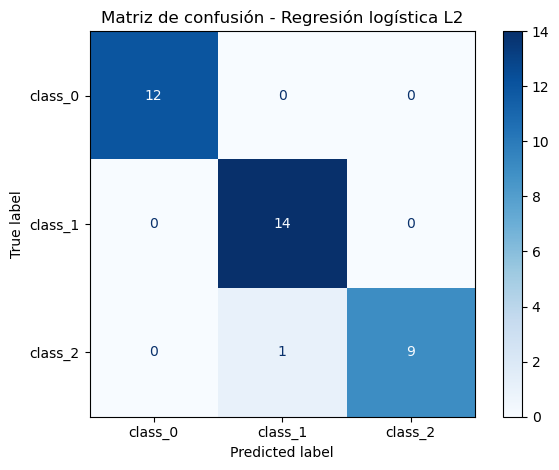

In [28]:
def evaluar_modelo(modelo, X_datos, y_real):
    predicciones = modelo.predict(X_datos)
    return accuracy_score(y_real, predicciones)

# Evaluación del modelo L2 seleccionado
pred_l2 = modelo_l2.predict(X_test_preparado)

print("Modelo L2 con C =", mejor_C_l2)

print("Accuracy entrenamiento L2:", round(evaluar_modelo(modelo_l2, X_train_preparado, y_train), 3))
print("Accuracy prueba L2:", round(evaluar_modelo(modelo_l2, X_test_preparado, y_test), 3))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, pred_l2, display_labels=wine.target_names, cmap="Blues", values_format="d")

plt.title("Matriz de confusión - Regresión logística L2")
plt.tight_layout()
plt.show()

## 7. Regresión logística con regularización L1 (tipo Lasso)

La regularización L1 penaliza la suma de los valores absolutos de los coeficientes. A diferencia de L2, puede llevar algunos coeficientes exactamente a cero. Este comportamiento puede servir como selección implícita de características.

Aunque aquí hablamos de una penalización de tipo Lasso, el modelo sigue siendo de clasificación logística; no se utiliza la clase `Lasso` de Scikit-learn, que está diseñada para regresión de una variable continua.

Se emplea `solver="saga"`, que permite regularización L1 para clasificación multiclase.

In [31]:
modelo_l1 = LogisticRegression(penalty="l1", solver="saga", C=0.1, max_iter=10000, random_state=42)
modelo_l1.fit(X_train_preparado, y_train)

pred_l1 = modelo_l1.predict(X_test_preparado)

print("Accuracy entrenamiento L1:", round(evaluar_modelo(modelo_l1, X_train_preparado, y_train), 3))
print("Accuracy prueba L1:", round(evaluar_modelo(modelo_l1, X_test_preparado, y_test), 3))

Accuracy entrenamiento L1: 0.972
Accuracy prueba L1: 1.0


### 7.1 Exploración manual del parámetro C

Se prueban distintos valores de `C` usando únicamente los datos de entrenamiento. Esta tabla sirve para ilustrar el efecto de la regularización, no para demostrar cuál valor generaliza mejor. Para seleccionar hiperparámetros rigurosamente se necesitaría un conjunto de validación o validación cruzada.

In [33]:
resultados_C = []
for C_valor in [0.01, 0.1, 1, 10]:
    modelo = LogisticRegression(penalty="l1", solver="saga", C=C_valor, max_iter=10000, random_state=42)
    modelo.fit(X_train_preparado, y_train)

    resultados_C.append({"C": C_valor, "Accuracy entrenamiento": evaluar_modelo(modelo, X_train_preparado, y_train)})

pd.DataFrame(resultados_C).round(3)

,C,Accuracy entrenamiento
0,0.01,0.331
1,0.10,0.972
2,1.00,1.000
3,10.00,1.000


### 7.2 Evaluación con accuracy y matriz de confusión

In [35]:
df_l1 = pd.DataFrame(resultados_C)
mejor_C_l1 = df_l1.loc[df_l1["Accuracy entrenamiento"].idxmax(), "C"]
print("Mejor C encontrado para L1:", mejor_C_l1)

Mejor C encontrado para L1: 1.0


In [ ]:
modelo_l1 = LogisticRegression(C=mejor_C_l1, solver="saga", l1_ratio=1, max_iter=5000, random_state=42)
modelo_l1.fit(X_train_preparado, y_train)

Accuracy entrenamiento L1: 0.972
Accuracy prueba L1: 1.0


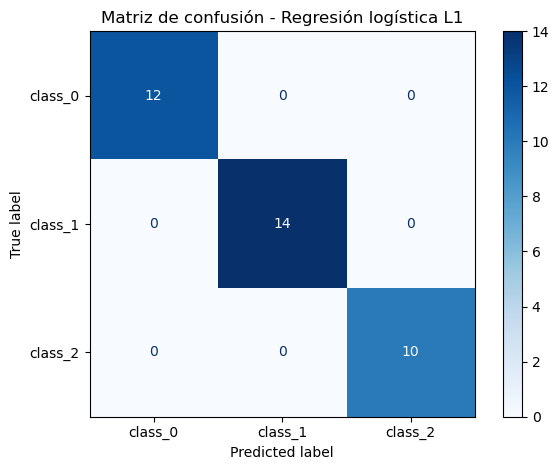

In [36]:
pred_l1 = modelo_l1.predict(X_test_preparado)

print("Accuracy entrenamiento L1:", round(evaluar_modelo(modelo_l1, X_train_preparado, y_train), 3))

print("Accuracy prueba L1:", round(evaluar_modelo(modelo_l1, X_test_preparado, y_test), 3))

ConfusionMatrixDisplay.from_predictions(y_test, pred_l1, display_labels=wine.target_names, cmap="Blues", values_format="d")

plt.title("Matriz de confusión - Regresión logística L1")
plt.tight_layout()
plt.show()

### 7.3 Inspección de coeficientes L1

En clasificación multiclase se estima un conjunto de coeficientes por clase. Un coeficiente igual a cero indica que esa variable no contribuye directamente a la puntuación lineal de esa clase, aunque puede conservar coeficientes no nulos para otras clases.

In [37]:
coeficientes_l1 = pd.DataFrame(modelo_l1.coef_.T, index=variables_predictoras, columns=[f"Clase {clase}" for clase in modelo_l1.classes_])
display(coeficientes_l1.round(3))
print("Variables con coeficiente cero en las tres clases:")
print(coeficientes_l1.index[(coeficientes_l1.abs() < 1e-8).all(axis=1)].tolist())

,Clase 0,Clase 1,Clase 2
alcohol,0.000,-0.734,0.000
malic_acid,0.000,0.000,0.000
ash,0.000,-0.133,0.000
alcalinity_of_ash,-0.011,0.000,0.000
magnesium,0.000,0.000,0.000
total_phenols,0.000,0.000,0.000
flavanoids,0.331,0.000,-0.838
nonflavanoid_phenols,0.000,0.000,0.000
proanthocyanins,0.000,0.000,0.000
color_intensity,0.000,-0.726,0.030


Variables con coeficiente cero en las tres clases:
['malic_acid', 'magnesium', 'total_phenols', 'nonflavanoid_phenols', 'proanthocyanins']


## 8. Comparación de los modelos

Se comparan tres modelos de regresión logística: uno sin regularización, otro con regularización L2 (C=1) y un tercero con regularización L1 (C=1). Estas configuraciones se utilizan para analizar el efecto de la regularización sobre el rendimiento de clasificación.

Se presentan los valores de accuracy obtenidos en los conjuntos de entrenamiento y prueba, así como las matrices de confusión calculadas sobre el conjunto de prueba.


In [38]:
comparacion = pd.DataFrame([
    {
        "Modelo": "Regresión logística sin regularización",
        "Accuracy entrenamiento": evaluar_modelo(modelo_sin_reg, X_train_preparado, y_train),
        "Accuracy prueba": evaluar_modelo(modelo_sin_reg, X_test_preparado, y_test)
    },
    {
        "Modelo": f"Regresión logística L2 (C={mejor_C_l2})",
        "Accuracy entrenamiento": evaluar_modelo(modelo_l2, X_train_preparado, y_train),
        "Accuracy prueba": evaluar_modelo(modelo_l2, X_test_preparado, y_test)
    },
    {
        "Modelo": f"Regresión logística L1 (C={mejor_C_l1})",
        "Accuracy entrenamiento": evaluar_modelo(modelo_l1, X_train_preparado, y_train),
        "Accuracy prueba": evaluar_modelo(modelo_l1, X_test_preparado, y_test)
    }
])

comparacion.round(3)

,Modelo,Accuracy entrenamiento,Accuracy prueba
0,Regresión logística sin regularización,1.000,0.972
1,Regresión logística L2 (C=1.0),1.000,0.972
2,Regresión logística L1 (C=1.0),0.972,1.000


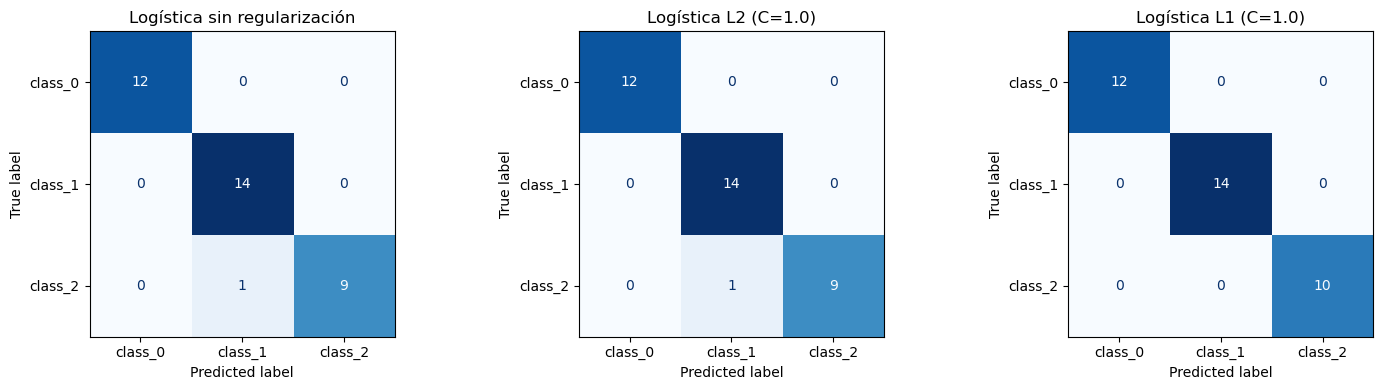

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pred_sin_reg = modelo_sin_reg.predict(X_test_preparado)

for ax, predicciones, titulo in zip(axes, [pred_sin_reg, pred_l2, pred_l1], 
                                    ["Logística sin regularización", f"Logística L2 (C={mejor_C_l2})", f"Logística L1 (C={mejor_C_l1})"]):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones, display_labels=wine.target_names, cmap="Blues",
        values_format="d", colorbar=False, ax=ax)
    ax.set_title(titulo)

plt.tight_layout()
plt.show()

## 9. Interpretación 

Los tres modelos de regresión logística presentan un buen rendimiento en la clasificación de los vinos. El modelo sin regularización y el modelo con regularización L2 (C=1) obtuvieron un accuracy de 1.0 en entrenamiento y 0.972 en prueba, lo que indica que clasificaron correctamente todas las observaciones de entrenamiento y 35 de las 36 observaciones de prueba.

Por su parte, el modelo con regularización L1 (C=1) alcanzó un accuracy de 0.972 en entrenamiento y 1.0 en prueba, clasificando correctamente todas las observaciones del conjunto de prueba.

Estos resultados muestran que la incorporación de regularización no necesariamente mejora el rendimiento predictivo. Sin embargo, la regularización L1 presenta una ventaja adicional: puede reducir algunos coeficientes a cero, permitiendo simplificar el modelo mediante una selección implícita de características.

Aunque L1 obtuvo el mayor accuracy en prueba, la diferencia corresponde solamente a una observación y no es suficiente para concluir que este modelo generaliza mejor. Además, el conjunto de datos es relativamente pequeño y los resultados pueden variar con una partición diferente.

En conclusión, los tres modelos mostraron una buena capacidad de clasificación para este conjunto de datos. La principal diferencia entre las configuraciones no está únicamente en su accuracy, sino también en cómo la regularización afecta los coeficientes y la complejidad del modelo.